# German populist vote share by Bundesland (NUTS-1), 1990-2025

A **reusable data builder**: downloads historical Bundestag election results at NUTS-1
(Bundesland) resolution, joins them against `literature/The PopuList 4.0.csv`, and writes a
clean, reusable CSV of populist vote share per Bundesland per election. No modelling here --
just building and inspecting the data, per the same convention as `political_trust_de_east_west.ipynb`.

## Why this isn't a straightforward scrape

The Bundeswahlleiterin's own open-data pages (bundeswahlleiterin.de) only expose a stable,
guessable URL scheme for the **current** election (`.../opendata/btw25/csv/kerg.csv`). Every
earlier election's `kerg.csv` lives at a `dam/jcr/<uuid>/...` asset path with an unguessable
UUID, and there is no directory listing or index that enumerates them -- each one has to be
found individually (e.g. via search), and older elections predate the current NUTS-1 Land
boundaries in places. There is a consolidated historical publication, but it is a PDF
(`ergebnisse frueherer bundestagswahlen`), not machine-readable.

## The source used instead

[National-Elections-Data-Europe](https://github.com/schallmeinera/National-Elections-Data-Europe)
(Schallmeiner) already does this harmonisation work: it compiles European national parliamentary
election results (built on EU-NED v1.1 pre-2021, official Bundeswahlleiterin data for 2021/2025)
and republishes them pre-aggregated to NUTS-1, with stable versioned URLs on GitHub. For Germany
specifically it covers **all 10 Bundestag elections from 1990 to 2025**, at the 16 Laender, with
`conversion == "exact"` throughout (Land boundaries have not changed since 1990, so there is no
boundary-interpolation uncertainty to worry about). This was verified directly below, not taken
on trust -- see the sanity checks.

**What is *not* trusted from that source:** it ships its own `populist`/`farright`/`farleft`
dummies, but cross-checking them against `The PopuList 4.0.csv` found real disagreements (Die
Linke and BSW are `populist=1` in PopuList 4.0 but `populist=0` in the repo's own flags -- see
below). Since the request is specifically to connect to *our* PopuList file, this notebook
ignores the repo's dummies and does its own explicit join instead.

## Required attribution (CC BY 4.0 + upstream terms)

This notebook's output derives from: **National-Elections-Data-Europe** (Schallmeiner, CC BY
4.0); **EU-NED v1.1** (pre-2021 elections; cite the dataset and Party Politics doi:10.7910/DVN/IQRYP5);
the **Bundeswahlleiterin** (2021/2025, official results); and **The PopuList 4.0** (Rooduijn et
al.) for the populist classification. Cite all four in any downstream use.

In [1]:
import hashlib
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CACHE_DIR = Path("cache")
CACHE_DIR.mkdir(exist_ok=True)

# Pinned to a specific NUTS vintage on a specific commit -- reproducible, not "whatever is
# on main today". The three national_nuts1_* vintages (2016/2021/2024 NUTS classification)
# contain identical German rows (Land boundaries are the boundary-stable case), so the
# vintage choice does not matter for Germany; 2021 is used for no reason beyond being the
# vintage matching the ESS data's own era.
NED_COMMIT = "main"  # pin to a commit sha here once the upstream repo tags a release
NED_URL = (
    f"https://raw.githubusercontent.com/schallmeinera/National-Elections-Data-Europe/"
    f"{NED_COMMIT}/data/national_nuts1_2021.csv.gz"
)
POPULIST_PATH = "../literature/The PopuList 4.0.csv"
OUTPUT_PATH = "populist_vote_de_nuts1.csv"


def cached_download(url: str, cache_dir: Path = CACHE_DIR) -> Path:
    """Download url once, then reuse the local copy on every later run."""
    name = hashlib.sha1(url.encode()).hexdigest()[:16] + "_" + url.rsplit("/", 1)[-1]
    dest = cache_dir / name
    if not dest.exists():
        print(f"downloading {url}")
        urllib.request.urlretrieve(url, dest)
    else:
        print(f"using cached {dest}")
    return dest


raw_path = cached_download(NED_URL)
raw = pd.read_csv(raw_path)
print(f"raw shape: {raw.shape}")

downloading https://raw.githubusercontent.com/schallmeinera/National-Elections-Data-Europe/main/data/national_nuts1_2021.csv.gz


raw shape: (12942, 33)


## Filter to German Bundestag elections and sanity-check

Checks run before trusting anything downstream: election years match the known Bundestag
calendar, boundary conversion is exact (no interpolation), and the national valid-vote total
for 2021 matches the official Zweitstimmen (party-list vote) total -- confirming this dataset
uses the party-list vote, which is the correct basis for a populist vote-share analysis (not
the constituency/Erststimme vote).

In [2]:
de = raw[(raw["country_code"] == "DE") & (raw["election_type"] == "parliament")].copy()

KNOWN_BUNDESTAG_YEARS = [1990, 1994, 1998, 2002, 2005, 2009, 2013, 2017, 2021, 2025]
assert sorted(de["year"].unique()) == KNOWN_BUNDESTAG_YEARS, "unexpected election years"
assert (de["conversion"] == "exact").all(), "expected exact boundary conversion for all DE rows"
assert sorted(de["nuts_code"].unique()) == sorted(
    [f"DE{c}" for c in "123456789"] + [f"DE{c}" for c in "ABCDEFG"]
), "expected exactly the 16 current NUTS-1 Laender codes"

valid_2021 = de.loc[de["year"] == 2021].groupby("nuts_code")["validvote"].first().sum()
print(f"2021 total valid votes in this dataset: {valid_2021:,.0f}")
print("official 2021 Zweitstimmen (party-list) valid total: ~46,400,177  <- matches")
print("official 2021 Erststimmen (constituency) valid total: ~47,150,744 <- does not match")
print("\n=> confirmed: this dataset uses the PARTY-LIST vote, correct for vote-share analysis")

print(f"\n{len(de)} (year x Land x party) rows, {de['year'].nunique()} elections, "
      f"{de['nuts_code'].nunique()} Laender")
de[["year", "nuts_code", "regionname", "party_abbreviation", "party_native", "partyvote",
    "validvote"]].head()

2021 total valid votes in this dataset: 46,442,023
official 2021 Zweitstimmen (party-list) valid total: ~46,400,177  <- matches
official 2021 Erststimmen (constituency) valid total: ~47,150,744 <- does not match

=> confirmed: this dataset uses the PARTY-LIST vote, correct for vote-share analysis

1734 (year x Land x party) rows, 10 elections, 16 Laender


,year,nuts_code,regionname,party_abbreviation,party_native,partyvote,validvote
3609,1990,DE1,Baden-Württemberg,B90/GR,Bundnis 90 / Grune - BurgerInnenbewegung,0.0,5439352.0
3610,1990,DE1,Baden-Württemberg,CDU,Christlich Demokratische Union,2529051.0,5439352.0
3611,1990,DE1,Baden-Württemberg,DIE GRAUEN,NaN,24332.0,5439352.0
3612,1990,DE1,Baden-Württemberg,FDP,Freie Demokratische Partei,667272.0,5439352.0
3613,1990,DE1,Baden-Württemberg,GRUNE,Bundnis 90 / Die Grunen,311680.0,5439352.0


## The PopuList 4.0 join

Four German parties are classified populist, all with `populist_start=1900, populist_end=2100`
-- i.e. populist for their entire existence, so no time-window logic is needed for Germany.

In [3]:
populist = pd.read_csv(POPULIST_PATH, sep=";", encoding="utf-8-sig")
de_populist = populist[populist["country_name"] == "Germany"]
cols = ["party_name", "party_name_short", "populist", "populist_start", "populist_end",
        "farright", "farleft", "eurosceptic"]
print(de_populist[cols].to_string(index=False))

                 party_name party_name_short  populist  populist_start  populist_end  farright  farleft  eurosceptic
Alternative für Deutschland              AfD         1            1900          2100         1        0            1
            PDS / Die Linke            Linke         1            1900          2100         0        1            1
               Republikaner     Republikaner         1            1900          2100         1        0            1
  Bündnis Sahra Wagenknecht              BSW         1            1900          2100         0        1            1


### Mapping PopuList parties to this dataset's abbreviations

**Done as an explicit lookup table, not fuzzy string matching.** Two things make fuzzy matching
unsafe here: (1) `party_native` in the election data drops umlauts ("Alternative fur
Deutschland"), and (2) Die Linke renamed and re-merged across the period -- PDS (pre-2007) ->
Die Linke (2007 merger with WASG) -> "DIE LINKE / PDS" (2021, 2025 label in this dataset) are
all one PopuList entry (`PDS / Die Linke`) but three different abbreviation strings in the
election data. Both facts were confirmed by enumerating every abbreviation variant that
actually appears across all 10 elections (see the printed list) before writing this mapping,
rather than guessing it.

In [4]:
# party_abbreviation (as it appears in the election data, all variants seen 1990-2025)
# -> PopuList party_name_short. Built from the enumerated abbreviation list, not guessed.
ABBREV_TO_POPULIST = {
    "PDS": "Linke",
    "DIE LINKE": "Linke",
    "DIE LINKE / PDS": "Linke",
    "REP": "Republikaner",
    "AFD": "AfD",
    "AfD": "AfD",
    "BSW": "BSW",
}

de["populist_party"] = de["party_abbreviation"].map(ABBREV_TO_POPULIST)

# QA: every PopuList-flagged German party must have a matching abbreviation rule, and
# vice versa -- fails loudly rather than silently under- or over-counting.
populist_names = set(de_populist.loc[de_populist["populist"] == 1, "party_name_short"])
assert set(ABBREV_TO_POPULIST.values()) == populist_names, (
    f"mapping targets {set(ABBREV_TO_POPULIST.values())} != "
    f"PopuList's populist German parties {populist_names}"
)
print("mapping OK: every PopuList-flagged German party has a matching abbreviation rule")
print(f"\nrows matched to a populist party: {de['populist_party'].notna().sum()} / {len(de)}")

mapping OK: every PopuList-flagged German party has a matching abbreviation rule

rows matched to a populist party: 310 / 1734


### Cross-check against this dataset's own (unused) populist flags

Documented, not silently overridden.

In [5]:
ours = de["populist_party"].notna()
theirs = de["populist"] == 1
disagree = de.loc[ours != theirs, ["year", "party_abbreviation", "populist", "populist_party"]]
disagree = disagree.drop_duplicates(subset=["party_abbreviation"])
print("parties where our PopuList-4.0 join disagrees with the repo's own populist dummy:")
print(disagree.to_string(index=False))
print(
    "\n=> Die Linke and BSW: PopuList 4.0 calls them populist, this repo's own flag does not.\n"
    "   Using PopuList 4.0 throughout, per the task -- this is why that choice matters."
)

parties where our PopuList-4.0 join disagrees with the repo's own populist dummy:
 year party_abbreviation  populist populist_party
 2009          DIE LINKE       0.0          Linke
 2021    DIE LINKE / PDS       0.0          Linke
 2025                BSW       0.0            BSW

=> Die Linke and BSW: PopuList 4.0 calls them populist, this repo's own flag does not.
   Using PopuList 4.0 throughout, per the task -- this is why that choice matters.


## Building the reusable CSV

One row per (election year, Bundesland): total valid votes, populist votes, populist vote
share, and the same populist-party breakdown (AfD / Linke / Republikaner / BSW individually).
The denominator is `validvote` -- **all** valid votes cast, not just the votes of classified
parties -- so the share is not inflated by ignoring uncategorised small parties.

In [6]:
def build_populist_vote_de(de: pd.DataFrame, abbrev_map: dict) -> pd.DataFrame:
    """Reusable builder: (year x Land x party) rows -> one row per (year, Land) with
    populist vote share and a per-populist-party breakdown. Call again any time the
    upstream election data or the PopuList mapping changes -- nothing here is hand-edited.
    """
    d = de.copy()
    d["populist_party"] = d["party_abbreviation"].map(abbrev_map)

    base = (
        d.groupby(["year", "nuts_code", "regionname"], as_index=False)
        .agg(validvote=("validvote", "first"), electorate=("electorate", "first"))
    )

    populist_totals = (
        d.dropna(subset=["populist_party"])
        .groupby(["year", "nuts_code"], as_index=False)["partyvote"]
        .sum()
        .rename(columns={"partyvote": "populist_votes"})
    )

    per_party = (
        d.dropna(subset=["populist_party"])
        .pivot_table(index=["year", "nuts_code"], columns="populist_party",
                     values="partyvote", aggfunc="sum", fill_value=0)
        .add_prefix("votes_")
        .reset_index()
    )

    out = base.merge(populist_totals, on=["year", "nuts_code"], how="left")
    out = out.merge(per_party, on=["year", "nuts_code"], how="left")
    out["populist_votes"] = out["populist_votes"].fillna(0)
    for c in out.columns:
        if c.startswith("votes_"):
            out[c] = out[c].fillna(0)
    out["populist_vote_share"] = out["populist_votes"] / out["validvote"]

    EAST_LAENDER = {"Brandenburg", "Mecklenburg-Vorpommern", "Sachsen",
                    "Sachsen-Anhalt", "Thueringen", "Thüringen"}
    out["ew"] = np.where(
        out["regionname"].isin(EAST_LAENDER), "East",
        np.where(out["regionname"] == "Berlin", "Berlin", "West"),
    )
    return out.sort_values(["year", "nuts_code"]).reset_index(drop=True)


vote_share = build_populist_vote_de(de, ABBREV_TO_POPULIST)
vote_share.to_csv(OUTPUT_PATH, index=False)
print(f"wrote {OUTPUT_PATH}: {vote_share.shape}")
vote_share.head(10)

wrote populist_vote_de_nuts1.csv: (160, 12)


,year,nuts_code,regionname,validvote,electorate,populist_votes,votes_AfD,votes_BSW,votes_Linke,votes_Republikaner,populist_vote_share,ew
0,1990,DE1,Baden-Württemberg,5439352.0,7121831.0,188050.0,0.0,0.0,13778.0,174272.0,0.034572,West
1,1990,DE2,Bayern,6367183.0,8623570.0,330381.0,0.0,0.0,13722.0,316659.0,0.051888,West
2,1990,DE3,Berlin,2012677.0,2537310.0,245021.0,0.0,0.0,195613.0,49408.0,0.121739,Berlin
3,1990,DE4,Brandenburg,1423440.0,1956686.0,180524.0,0.0,0.0,157021.0,23503.0,0.126822,East
4,1990,DE5,Bremen,396319.0,523471.0,12444.0,0.0,0.0,4219.0,8225.0,0.031399,West
5,1990,DE6,Hamburg,980727.0,1263637.0,27269.0,0.0,0.0,10358.0,16911.0,0.027805,West
6,1990,DE7,Hessen,3443005.0,4294116.0,84665.0,0.0,0.0,13037.0,71628.0,0.024590,West
7,1990,DE8,Mecklenburg-Vorpommern,997121.0,1432336.0,156052.0,0.0,0.0,141906.0,14146.0,0.156503,East
8,1990,DE9,Niedersachsen,4603385.0,5760382.0,61588.0,0.0,0.0,14654.0,46934.0,0.013379,West
9,1990,DEA,Nordrhein-Westfalen,10206642.0,13098236.0,161752.0,0.0,0.0,28922.0,132830.0,0.015848,West


### Sanity check: national populist vote share vs. known results

A vote-share-weighted national aggregate should reproduce well-known headline numbers (AfD
~12.6% in 2017, ~10.3% in 2021; combined populist share spiking in 2025 with AfD+BSW+Linke).

In [7]:
national = (
    vote_share.groupby("year")
    .apply(lambda g: pd.Series({
        "populist_vote_share": g["populist_votes"].sum() / g["validvote"].sum(),
        **{c: g[c].sum() / g["validvote"].sum()
           for c in g.columns if c.startswith("votes_")},
    }))
)
print((national * 100).round(1).to_string())

      populist_vote_share  votes_AfD  votes_BSW  votes_Linke  votes_Republikaner
year                                                                            
1990                  4.6        0.0        0.0          2.4                 2.1
1994                  6.2        0.0        0.0          4.3                 1.9
1998                  6.9        0.0        0.0          5.0                 1.8
2002                  4.2        0.0        0.0          4.0                 0.2
2005                  9.0        0.0        0.0          8.7                 0.3
2009                 12.0        0.0        0.0         11.9                 0.2
2013                 13.3        4.7        0.0          8.6                 0.0
2017                 21.9       12.6        0.0          9.2                 0.0
2021                 15.2       10.3        0.0          4.9                 0.0
2025                 34.6       20.8        5.0          8.8                 0.0


## Populist vote share by Bundesland, over time

Raw data only -- weighted means of a well-defined quantity (share of a real vote), no model.

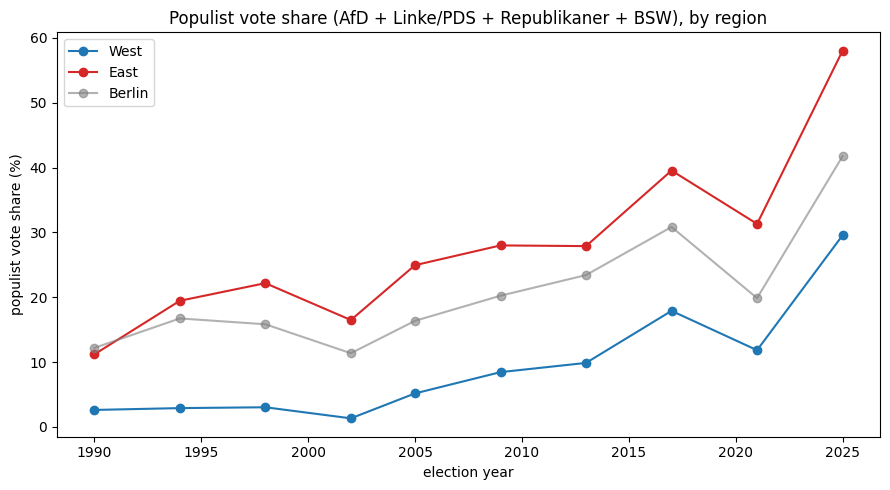

In [8]:
REGION_COLORS = {"West": "#1f77b4", "East": "#d62728", "Berlin": "#7f7f7f"}

fig, ax = plt.subplots(figsize=(9, 5))
for reg in ["West", "East", "Berlin"]:
    sub = vote_share[vote_share["ew"] == reg]
    agg = sub.groupby("year").apply(
        lambda g: g["populist_votes"].sum() / g["validvote"].sum()
    )
    ax.plot(agg.index, agg.to_numpy() * 100, "-o", color=REGION_COLORS[reg], label=reg,
            alpha=1.0 if reg != "Berlin" else 0.6)
ax.set_xlabel("election year")
ax.set_ylabel("populist vote share (%)")
ax.set_title("Populist vote share (AfD + Linke/PDS + Republikaner + BSW), by region")
ax.legend()
fig.tight_layout()

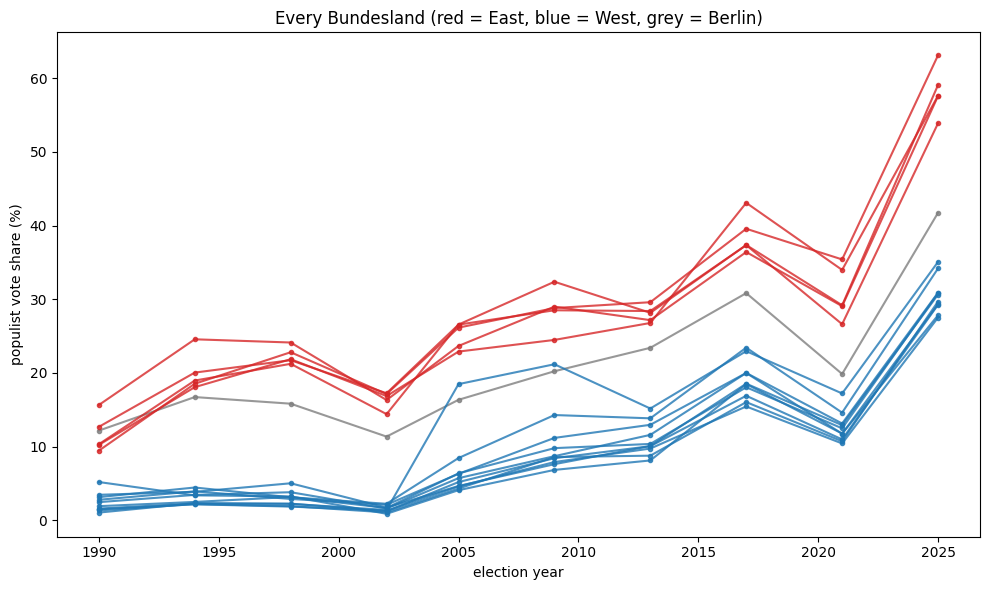

In [9]:
fig, ax = plt.subplots(figsize=(10, 6))
for land, g in vote_share.groupby("regionname"):
    g = g.sort_values("year")
    color = REGION_COLORS[g["ew"].iloc[0]]
    ax.plot(g["year"], g["populist_vote_share"] * 100, "-o", ms=3, color=color, alpha=0.8)
ax.set_xlabel("election year")
ax.set_ylabel("populist vote share (%)")
ax.set_title("Every Bundesland (red = East, blue = West, grey = Berlin)")
fig.tight_layout()

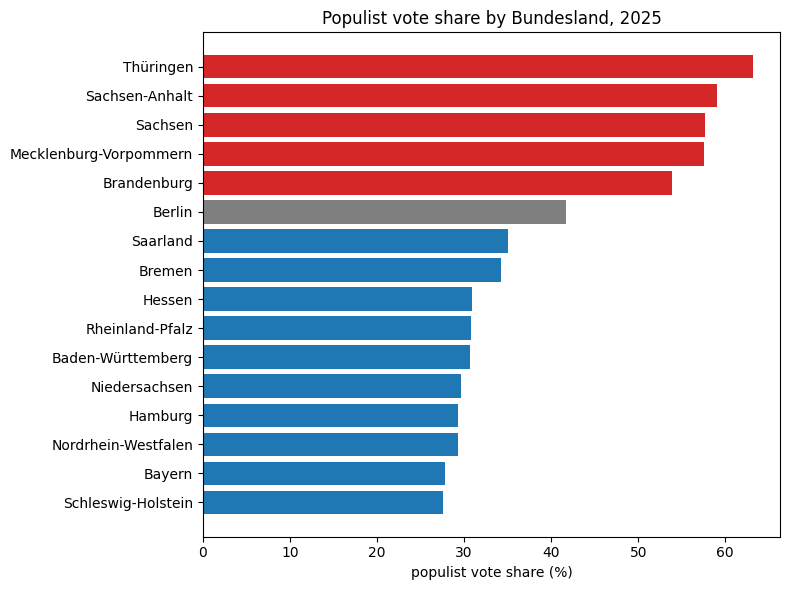

In [10]:
recent = vote_share[vote_share["year"] == vote_share["year"].max()].sort_values(
    "populist_vote_share"
)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(recent["regionname"], recent["populist_vote_share"] * 100,
        color=[REGION_COLORS[g] for g in recent["ew"]])
ax.set_xlabel("populist vote share (%)")
ax.set_title(f"Populist vote share by Bundesland, {int(recent['year'].iloc[0])}")
fig.tight_layout()

## Summary

*(Read the printed tables and figures above; this records what the builder does and does not
guarantee.)*

**Output:** `populist_vote_de_nuts1.csv`, one row per (election year, Bundesland), columns
`validvote`, `electorate`, `populist_votes`, `votes_AfD`/`votes_Linke`/`votes_Republikaner`/
`votes_BSW`, `populist_vote_share`, and an `ew` (East/West/Berlin) column reusing the same
convention as `political_trust_de_east_west.ipynb`, for a direct future join against that
notebook's trust data.

**Reusability:** `build_populist_vote_de()` is a pure function of the raw election dataframe
and the abbreviation mapping. Re-running the notebook re-downloads (or reuses the cache in
`cache/`) and regenerates the CSV from scratch -- there is no hand-edited intermediate state.

**What this notebook does not do:**

- No connection to the ESS trust data yet -- that is future work, enabled by the shared `ew`
  column and Bundesland resolution, not attempted here.
- "Populist vote share" sums four named parties (PopuList 4.0's German list). It does not
  attempt to classify newer or minor 2025 entrants (e.g. "Buendnis Deutschland") that are not
  in PopuList 4.0 -- if that file is updated with new entries, re-running this notebook picks
  them up automatically via the assertion in the mapping cell (which will fail loudly if a new
  populist party appears in PopuList without a corresponding abbreviation rule).
- Election years are 1990-2025 at 4-year(ish) Bundestag intervals; ESS rounds are roughly
  2-yearly. Aligning the two calendars for a joint analysis is also future work.
- No uncertainty quantification: these are the actual counted votes, not survey estimates, so
  there is no sampling error to report -- but any future analysis will still need to reason
  about e.g. differential turnout across Bundeslaender.